# 02 Modelling: joint fits of forced fusion, causal inference and cue switching

**Main difference from v1**: the unimodal blocks and the main experiment are fitted together (`avdur_analysis.fitting`).
σ_A(low), σ_A(high) and σ_V are therefore constrained by both, instead of being fixed from the unimodal fits or freed in the
bimodal fit only.

* Models (`avdur_analysis.models`) are v1's lognormal versions: measurements in log time, a boxcar prior on
  [50 ms, 2000 ms], an estimate per interval, "test longer" if the test estimate is larger, lapse λ/2.
  σ's are **single-interval** noises, so a unimodal psychometric σ is √2 × σ (checked below).
* P("test longer") is computed exactly (fusion, switching) or by deterministic quadrature (causal inference), with no
  Monte Carlo. Repeated evaluations of a likelihood are therefore identical: a summed ΔAIC has no evaluation noise
  (a reviewer's question on v1). The fusion and switching probabilities take milliseconds; causal inference takes ~0.1 s.
* Fits: L-BFGS-B from 6 starts. `n_near_best` counts the starts within 0.5 of the best −log L. Saved with every start,
  the settings and the data files in `results/model_fits/<complete|partial>/`.
* Predicted PSE and σ (figures 5-6): a psychometric fit to the model's expected answers at the participant's own
  tested stimuli, as the data are fitted. This is the deterministic counterpart of v1's simulate-and-refit.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from avdur_analysis import data as D, fitting as F, models as M, psychometric as P, style as St
%matplotlib inline
St.setup(scale=0.8)
plt.rcParams["figure.dpi"] = 80
pd.set_option("display.width", 220, "display.max_columns", 40)
WHO = "group"        # participant ID, "group" or "all" for figures 5-7
ERRORBAR = "auto"
CRIT = "aic"         # "aic" or "bic"
WORKERS = 6          # parallel fits when something has to be (re)fitted

## Double checks
Every check below should show a small `max_abs_diff`:
* **v1 parts**: truncated mean, posterior of a common cause, and the causal-inference estimate against v1's `monteCarloClass`.
* **Probabilities**: P(test longer) of each model against 10⁶-draw Monte Carlo, both ours and v1's `probTestLonger_vectorized_mc`.
  Compare with `mc_se`.
* **Quadrature assumption**: the causal estimate increases with m_A, which the quadrature relies on.
* **2IFC √2**: a psychometric fit to simulated unimodal answers returns √2 × the single-interval σ.
* **Log-time weighting**: the fusion PSE is 0.5^w_A·(0.5 + c)^w_V. `linear_rule_ms_off` shows how far a linear-time
  weighting would be.

In [2]:
from avdur_analysis import verify as V
checks = V.run_all()
checks.round(5)

,check,case,max_abs_diff,exact,mc,linear_rule_ms_off,mc_se,v1_mc,diff_v1
0,v1 tn_mean,sA=0.1 sV=0.3 p=0.7; 64 far draws left out,0.00000,NaN,NaN,NaN,NaN,NaN,NaN
1,v1 posterior C=1,sA=0.1 sV=0.3 p=0.7; 64 far draws left out,0.00000,NaN,NaN,NaN,NaN,NaN,NaN
2,v1 causal estimate,sA=0.1 sV=0.3 p=0.7; 64 far draws left out,0.00000,NaN,NaN,NaN,NaN,NaN,NaN
3,v1 tn_mean,sA=0.45 sV=0.3 p=0.5; 2 far draws left out,0.00000,NaN,NaN,NaN,NaN,NaN,NaN
4,v1 posterior C=1,sA=0.45 sV=0.3 p=0.5; 2 far draws left out,0.00000,NaN,NaN,NaN,NaN,NaN,NaN
5,v1 causal estimate,sA=0.45 sV=0.3 p=0.5; 2 far draws left out,0.00000,NaN,NaN,NaN,NaN,NaN,NaN
6,v1 tn_mean,sA=0.8 sV=0.25 p=0.9; 13 far draws left out,0.00000,NaN,NaN,NaN,NaN,NaN,NaN
7,v1 posterior C=1,sA=0.8 sV=0.25 p=0.9; 13 far draws left out,0.00000,NaN,NaN,NaN,NaN,NaN,NaN
8,v1 causal estimate,sA=0.8 sV=0.25 p=0.9; 13 far draws left out,0.00000,NaN,NaN,NaN,NaN,NaN,NaN
9,v1 tn_mean,sA=0.25 sV=0.6 p=0.3; 6 far draws left out,0.00000,NaN,NaN,NaN,NaN,NaN,NaN


## Joint fits

In [3]:
fits = F.fit_all(workers=WORKERS)
from avdur_analysis import model_figures as MF
MF.param_table(fits).round(3)

,participant,status,model,nll,aic,bic,n_params,n_near_best,at_bound,lapse,sigma_a_low,sigma_a_high,sigma_v,p_c,p_switch_low,p_switch_high
0,MZ,complete,fusion,1241.294,2490.587,2513.879,4,5,,0.060,0.183,0.371,0.598,NaN,NaN,NaN
1,MZ,complete,causal,1235.201,2480.401,2509.516,5,6,,0.054,0.188,0.377,0.479,1.000,NaN,NaN
2,MZ,complete,switching,1238.375,2488.750,2523.687,6,6,,0.035,0.167,0.294,0.322,NaN,0.134,0.381
3,KJ,partial,fusion,809.489,1626.978,1648.650,4,6,,0.013,0.213,0.336,0.646,NaN,NaN,NaN
4,KJ,partial,causal,809.489,1628.978,1656.068,5,6,p_c,0.013,0.213,0.336,0.646,1.000,NaN,NaN
5,KJ,partial,switching,817.265,1646.529,1679.038,6,6,,0.009,0.171,0.253,0.425,NaN,0.171,0.325
6,BQ,complete,fusion,1399.875,2807.751,2831.052,4,6,,0.116,0.290,0.732,0.851,NaN,NaN,NaN
7,BQ,complete,causal,1391.813,2793.626,2822.753,5,6,,0.087,0.337,1.079,0.478,0.673,NaN,NaN
8,BQ,complete,switching,1390.091,2792.183,2827.134,6,6,,0.095,0.310,0.634,0.298,NaN,0.022,0.411
9,EK,partial,fusion,573.197,1154.394,1174.595,4,6,,0.106,0.197,0.269,0.555,NaN,NaN,NaN


## Figure 1: predicted optimal-integration σ against the observed audiovisual σ
Psychometric σ of the unimodal blocks combined optimally, σ_A σ_V / √(σ_A² + σ_V²), against the bimodal σ at 0 conflict
(`observed="mean"` averages over conflicts). Only participants with both unimodal blocks are shown.

In [4]:
MF.optimal_table().round(3)

,participant,noise,sigma_a,sigma_v,predicted,observed,better_cue,predicted_lo,predicted_hi,observed_lo,observed_hi
0,MZ,0.1,0.128,0.488,0.124,0.330,0.128,0.076,0.185,0.208,0.511
1,MZ,1.0,0.467,0.488,0.338,0.383,0.467,0.259,0.432,0.257,0.560
2,BQ,0.1,0.277,0.409,0.229,0.724,0.277,0.173,0.308,0.414,1.326
3,BQ,1.0,0.800,0.409,0.364,0.506,0.409,0.256,0.520,0.286,1.027
4,EK,0.1,0.295,0.305,0.212,0.430,0.295,0.159,0.265,0.132,1.109
5,EK,1.0,0.548,0.305,0.267,1.568,0.305,0.190,0.349,0.472,5.000


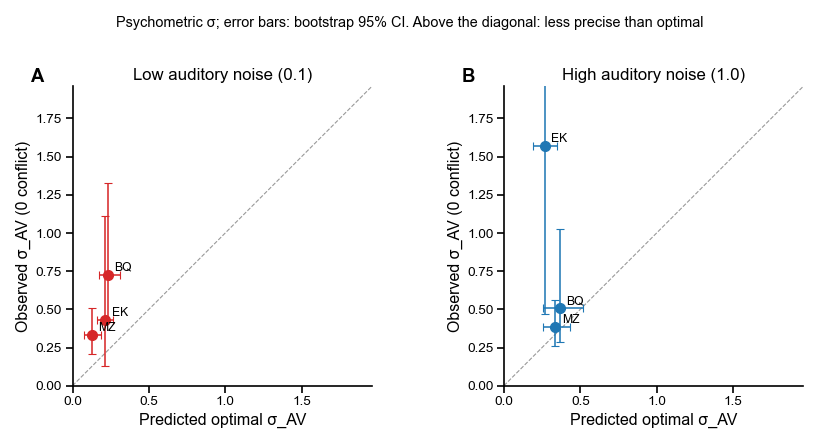

In [5]:
fig = MF.fig1_optimal_integration("matched")
plt.show()

## Figures 2-4: model comparison (ΔAIC relative to forced fusion; negative favours the model)

In [6]:
MF.delta_aic(fits, crit=CRIT).round(2)

model,fusion,causal,switching
participant,,,
MZ,0.0,-10.19,-1.84
KJ,0.0,2.00,19.55
BQ,0.0,-14.12,-15.57
EK,0.0,-7.19,-15.38


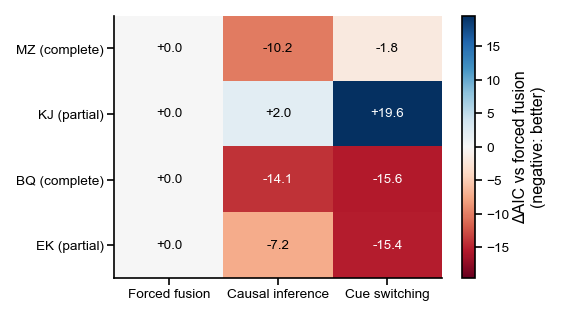

In [7]:
fig = MF.fig2_aic_heatmap(fits, crit=CRIT)
plt.show()

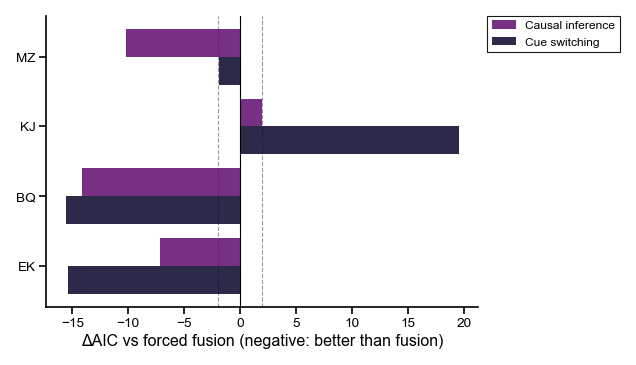

In [8]:
fig = MF.fig3_delta_aic_bars(fits, crit=CRIT)
plt.show()

In [9]:
MF.group_delta(fits, crit=CRIT).round(2)

,model,summed,lo,hi,n_participants,n_better
0,fusion,0.00,0.00,0.00,4,0
1,causal,-29.50,-49.56,-4.19,4,3
2,switching,-13.23,-61.89,43.28,4,3


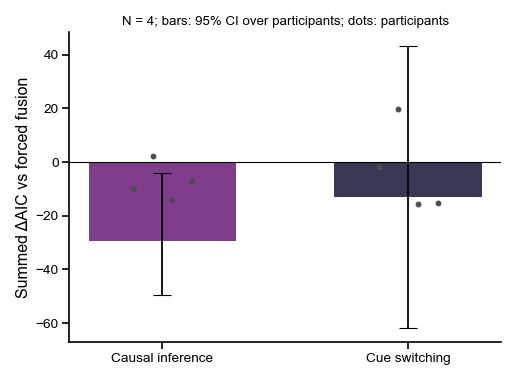

In [10]:
fig = MF.fig4_group_delta_aic(fits, crit=CRIT)
plt.show()

## Figures 5-6: measured and model-predicted PSE shift and σ against conflict

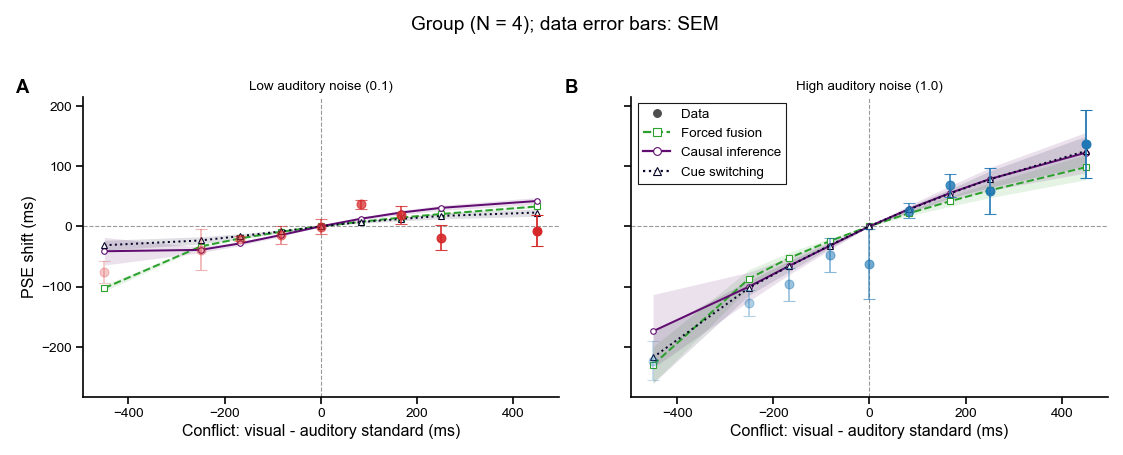

In [11]:
fig = MF.fig5_pse_models(WHO, errorbar=ERRORBAR)
plt.show()

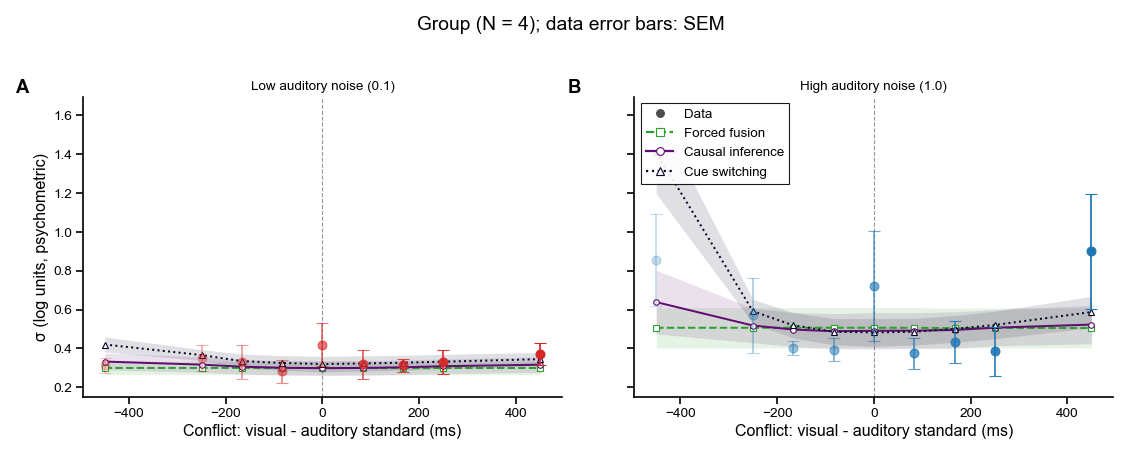

In [12]:
fig = MF.fig6_sigma_models(WHO, errorbar=ERRORBAR)
plt.show()

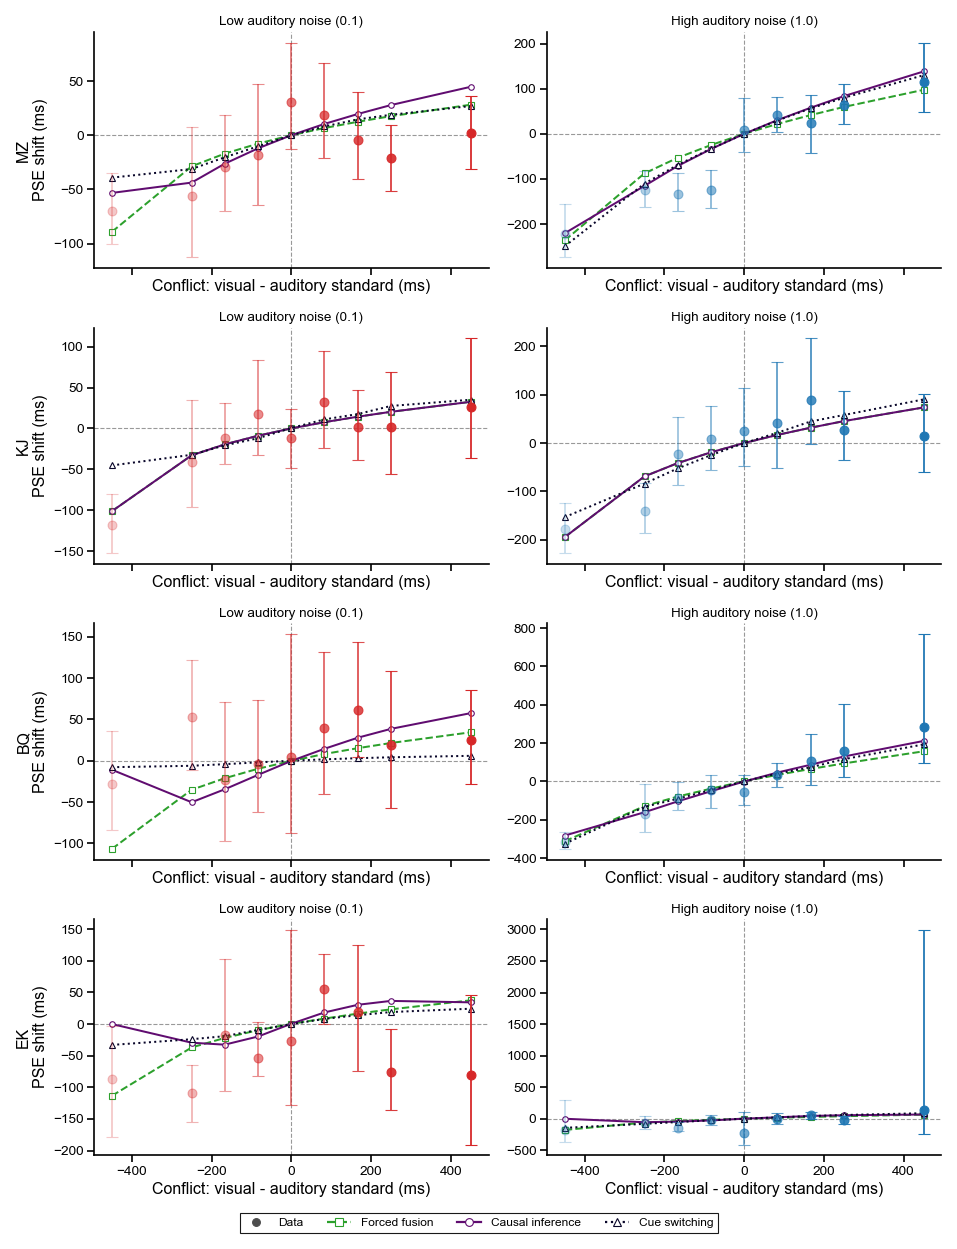

In [13]:
fig = MF.fig5_pse_models("all")
plt.show()

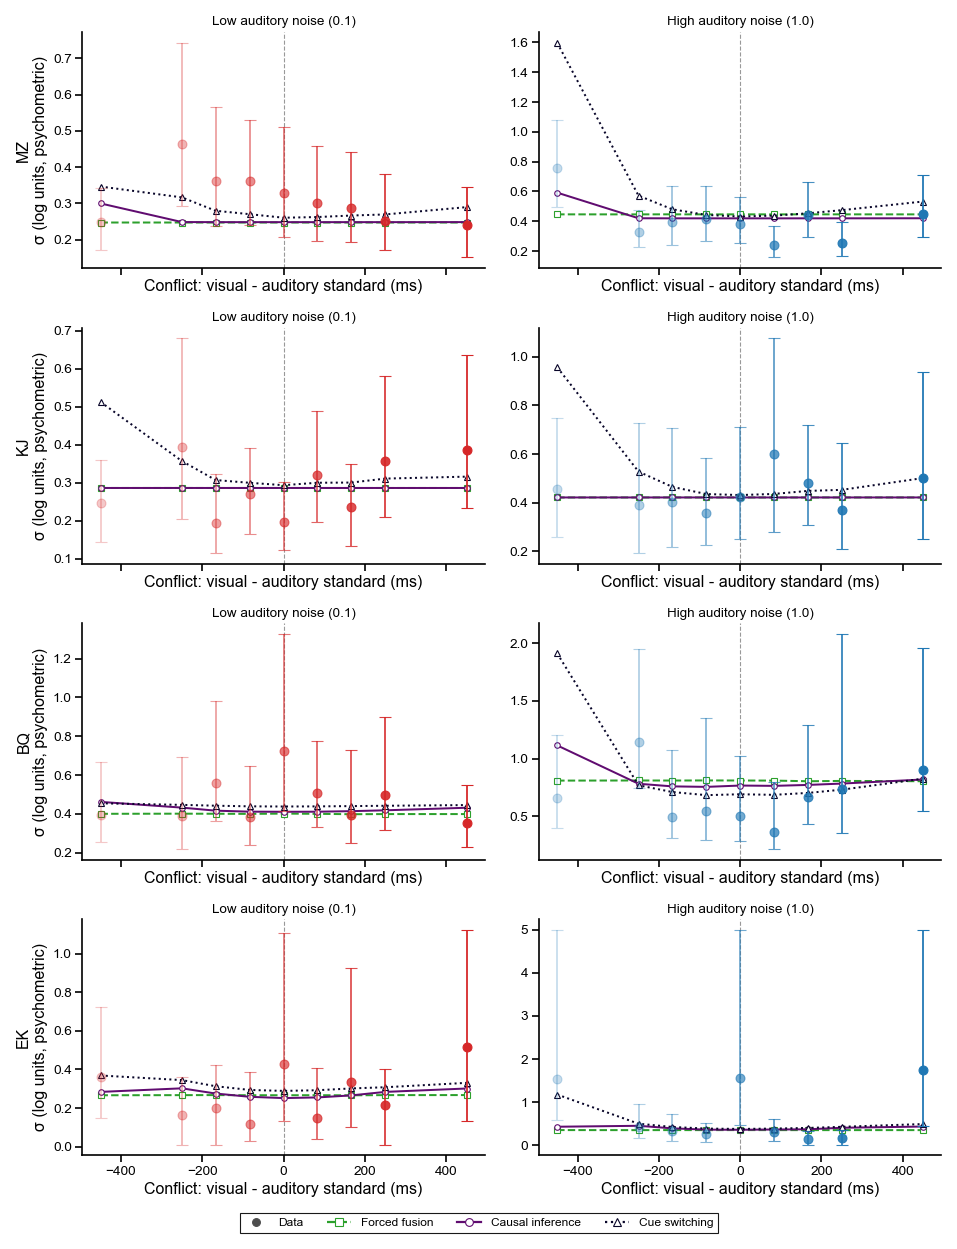

In [14]:
fig = MF.fig6_sigma_models("all")
plt.show()

## Figure 7: posterior probability of a common cause across conflicts (v1 figure 13)
Causal-inference fits: the posterior P(C = 1) for the standard interval, averaged over its measurements. Dashed: the fitted prior p_c.

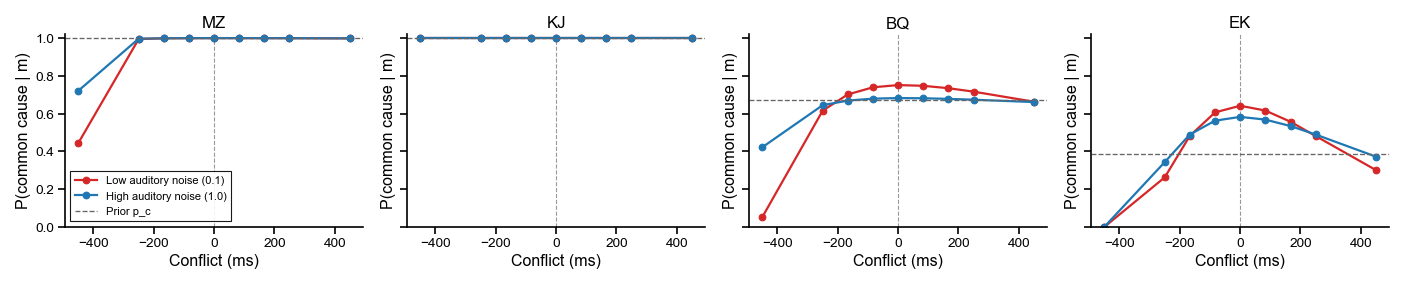

In [15]:
fig = MF.fig7_posterior_common("all")
plt.show()

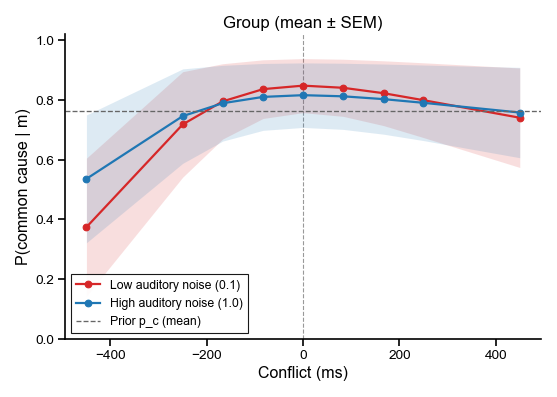

In [16]:
fig = MF.fig7_posterior_common("group")
plt.show()